# Phase 1 baseline: H&E patches → ResNet-50 → Ridge → 50 genes

**Dataset:** HEST-Benchmark, IDC task (4 samples, 4 official patient-held-out folds).

**Pipeline:** 224×224 H&E patch → frozen ImageNet ResNet-50 (2,048-d features) → StandardScaler → Ridge regression → log1p expression of the 50 genes in `var_50genes.json`.

**Evaluation:** per-gene Pearson correlation across the spots of the held-out patient, for each fold, compared with a shuffled-label control.

In [1]:
import json
import time
from importlib.metadata import version
from pathlib import Path

import anndata as ad
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision
from matplotlib.colors import ListedColormap
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from torchvision.models import ResNet50_Weights, resnet50

DATA_DIR = Path("data/hest-bench/IDC")
FEATURE_DIR = Path("features")
RESULTS_DIR = Path("results")
ALPHAS = np.logspace(-1, 6, 15)
SEED = 0

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")  # Apple GPU if available, otherwise CPU
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| sklearn", sklearn.__version__, "| anndata", version("anndata"))
print("device:", device)

torch 2.14.1 | torchvision 0.29.1 | sklearn 1.9.1 | anndata 0.12.19
device: mps


## 1. Inspect the data

### Official splits
Each fold holds out one sample (patient) for testing and trains on the other three.

In [2]:
splits = {}
for fold in range(4):
    for part in ["train", "test"]:
        splits[(fold, part)] = pd.read_csv(DATA_DIR / "splits" / f"{part}_{fold}.csv")
        print(f"fold {fold} {part:5s}:", splits[(fold, part)]["sample_id"].tolist())

SAMPLES = sorted(set(splits[(0, "train")]["sample_id"]) | set(splits[(0, "test")]["sample_id"]))

test_ids = []
for fold in range(4):
    train_ids = splits[(fold, "train")]["sample_id"].tolist()
    test_id = splits[(fold, "test")]["sample_id"].tolist()
    assert len(train_ids) == 3 and len(test_id) == 1, f"fold {fold}: unexpected split sizes"
    assert test_id[0] not in train_ids, f"fold {fold}: test sample also in training"
    assert set(train_ids) | set(test_id) == set(SAMPLES), f"fold {fold}: does not cover all samples"
    for _, row in pd.concat([splits[(fold, "train")], splits[(fold, "test")]]).iterrows():
        assert row["patches_path"] == f"patches/{row['sample_id']}.h5" and row["expr_path"] == f"adata/{row['sample_id']}.h5ad"
    test_ids.append(test_id[0])
assert sorted(test_ids) == SAMPLES, "each sample should be held out exactly once"

print("\nsamples:", SAMPLES)
print("checks passed: 3 train + 1 test per fold, no overlap, every sample held out exactly once")

fold 0 train: ['TENX95', 'NCBI785', 'NCBI783']
fold 0 test : ['TENX99']
fold 1 train: ['TENX99', 'NCBI785', 'NCBI783']
fold 1 test : ['TENX95']
fold 2 train: ['TENX99', 'TENX95', 'NCBI783']
fold 2 test : ['NCBI785']
fold 3 train: ['TENX99', 'TENX95', 'NCBI785']
fold 3 test : ['NCBI783']

samples: ['NCBI783', 'NCBI785', 'TENX95', 'TENX99']
checks passed: 3 train + 1 test per fold, no overlap, every sample held out exactly once


### Gene list

In [3]:
GENES = json.load(open(DATA_DIR / "var_50genes.json"))["genes"]
assert len(GENES) == 50 and len(set(GENES)) == 50
print(len(GENES), "genes:", ", ".join(GENES))

50 genes: ABCC11, ADH1B, ADIPOQ, ANKRD30A, AQP1, AQP3, CCR7, CD3E, CEACAM6, CEACAM8, CLIC6, CYTIP, DST, ERBB2, ESR1, FASN, GATA3, IL2RG, IL7R, KIT, KLF5, KRT14, KRT5, KRT6B, MMP1, MMP12, MS4A1, MUC6, MYBPC1, MYH11, MYLK, OPRPN, OXTR, PIGR, PTGDS, PTN, PTPRC, SCD, SCGB2A1, SERHL2, SERPINA3, SFRP1, SLAMF7, TACSTD2, TCL1A, TENT5C, TOP2A, TPSAB1, TRAC, VWF


### Per-sample files
Patch arrays are only inspected through their HDF5 metadata here; images are never loaded all at once.

In [4]:
rows = []
for s in SAMPLES:
    with h5py.File(DATA_DIR / "patches" / f"{s}.h5", "r") as f:
        img = f["img"]
        patch_info = {"patches shape": img.shape, "patches dtype": str(img.dtype),
                      "patch size at full res (px)": int(img.attrs["patch_size"]), "h5 keys": list(f.keys())}
    a = ad.read_h5ad(DATA_DIR / "adata" / f"{s}.h5ad")
    X = np.asarray(a.X)
    rows.append({"sample": s, **patch_info,
                 "expr shape": X.shape, "expr dtype": str(X.dtype),
                 "all integers": bool(np.all(X == np.round(X))), "min": X.min(), "max": X.max(),
                 "row sums == obs total_counts": bool(np.allclose(X.sum(axis=1), a.obs["total_counts"])),
                 "% zeros": round(100 * float(np.mean(X == 0)), 1),
                 "control probes": int(a.var_names.str.contains("NegControl|BLANK|Unassigned").sum())})
pd.DataFrame(rows).set_index("sample")

,patches shape,patches dtype,patch size at full res (px),h5 keys,expr shape,expr dtype,all integers,min,max,row sums == obs total_counts,% zeros,control probes
sample,,,,,,,,,,,,
NCBI783,"(3005, 224, 224, 3)",uint8,409,"[barcode, coords, img]","(3869, 541)",uint16,True,0,2364,True,62.9,253
NCBI785,"(4010, 224, 224, 3)",uint8,308,"[barcode, coords, img]","(4180, 541)",uint16,True,0,2385,True,44.2,220
TENX95,"(7760, 224, 224, 3)",uint8,527,"[barcode, coords, img]","(11845, 541)",uint16,True,0,2268,True,64.2,261
TENX99,"(20761, 224, 224, 3)",uint8,527,"[barcode, coords, img]","(25080, 541)",uint16,True,0,1703,True,64.2,261


**Normalization:** the expression matrices are non-negative integers whose row sums equal `obs["total_counts"]`, so they are **raw, unnormalized counts**.
The `.h5ad` files contain more spots than the patch files, so patches must be matched to spots by barcode.

### Example patches

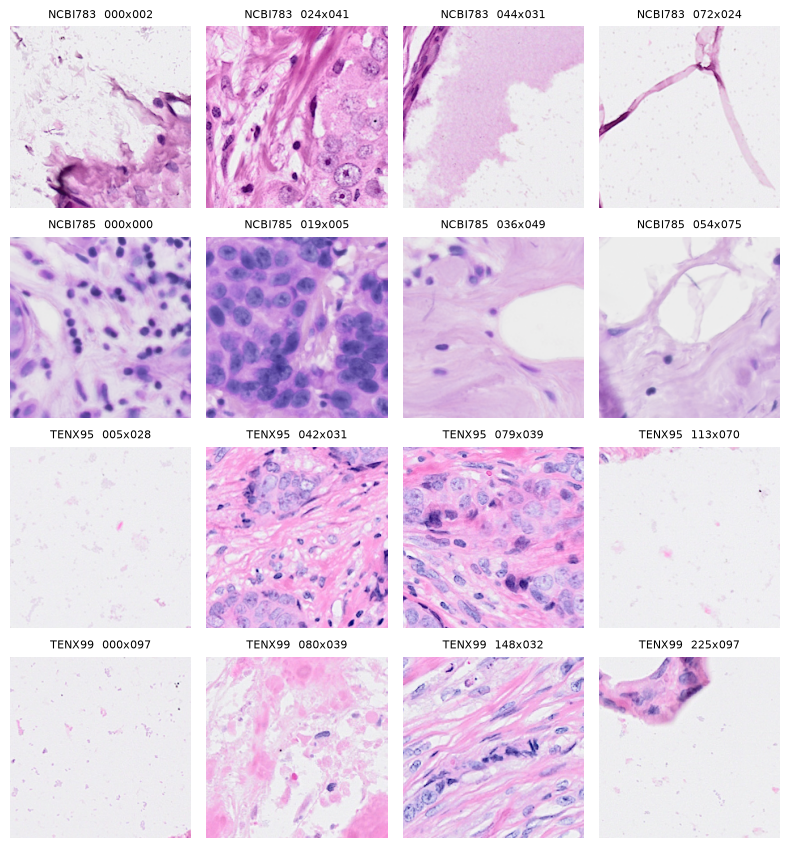

In [5]:
fig, axes = plt.subplots(len(SAMPLES), 4, figsize=(8, 8.6))
for r, s in enumerate(SAMPLES):
    with h5py.File(DATA_DIR / "patches" / f"{s}.h5", "r") as f:
        for c, i in enumerate(np.linspace(0, f["img"].shape[0] - 1, 4).astype(int)):
            axes[r, c].imshow(f["img"][i])  # reads a single patch
            axes[r, c].set_title(f"{s}  {f['barcode'][i, 0].decode()}", fontsize=8)
            axes[r, c].axis("off")
plt.tight_layout()
plt.show()

## 2. Align patches and expression

Expression rows are matched to patches by barcode (`barcode` in the patch file, `obs_names` in the `.h5ad`), never by row position.
As an independent check, each patch's stored coordinates must equal its spot's pixel position in the `.h5ad` (the patch file stores them in `(pxl_row_in_fullres, pxl_col_in_fullres)` order).

In [6]:
def read_patch_barcodes(s):
    with h5py.File(DATA_DIR / "patches" / f"{s}.h5", "r") as f:
        barcodes = np.array([b.decode() for b in f["barcode"][:, 0]])
        coords = f["coords"][:]
    return barcodes, coords


expr = {}  # sample -> AnnData with rows in patch order
rows = []
for s in SAMPLES:
    barcodes, coords = read_patch_barcodes(s)
    a = ad.read_h5ad(DATA_DIR / "adata" / f"{s}.h5ad")
    patch_set, expr_set = set(barcodes), set(a.obs_names)
    row = {"sample": s, "patches": len(barcodes), "expression spots": a.n_obs,
           "duplicate patch barcodes": len(barcodes) - len(patch_set),
           "duplicate expression barcodes": a.n_obs - len(expr_set),
           "overlap": len(patch_set & expr_set),
           "patches without expression": len(patch_set - expr_set),
           "expression spots without patch": len(expr_set - patch_set)}
    assert row["duplicate patch barcodes"] == 0 and row["duplicate expression barcodes"] == 0, f"{s}: duplicate barcodes"
    assert row["patches without expression"] == 0, f"{s}: some patches have no expression row - stop and investigate"

    # Reorder expression rows into patch order by barcode
    idx = a.obs_names.get_indexer(barcodes)
    a = a[idx].copy()
    assert np.array_equal(a.obs_names.to_numpy(), barcodes)

    spot_xy = a.obs[["pxl_row_in_fullres", "pxl_col_in_fullres"]].to_numpy()
    row["max coord offset (px)"] = float(np.abs(coords - spot_xy).max())
    assert row["max coord offset (px)"] <= 1, f"{s}: patch coordinates disagree with spot positions"

    expr[s] = a
    rows.append(row)

display(pd.DataFrame(rows).set_index("sample"))
print("All patch barcodes are unique, matched to exactly one expression spot, and positions agree within 1 px.")
print("Expression spots without a patch are dropped (as in the official benchmark, which indexes adata by patch barcodes).")

,patches,expression spots,duplicate patch barcodes,duplicate expression barcodes,overlap,patches without expression,expression spots without patch,max coord offset (px)
sample,,,,,,,,
NCBI783,3005,3869,0,0,3005,0,864,0.993832
NCBI785,4010,4180,0,0,4010,0,170,0.993153
TENX95,7760,11845,0,0,7760,0,4085,0.989481
TENX99,20761,25080,0,0,20761,0,4319,0.997074


All patch barcodes are unique, matched to exactly one expression spot, and positions agree within 1 px.
Expression spots without a patch are dropped (as in the official benchmark, which indexes adata by patch barcodes).


## 3. Prepare targets

**Official preprocessing.** In the HEST benchmark code, `load_adata(expr_path, genes, barcodes, normalize=True)` (`src/hest/bench/st_dataset.py`, default `normalize: bool = True` in `benchmark.py`) selects the genes and patch barcodes, then calls `normalize_adata`, which applies **only `sc.pp.log1p` to the raw counts** (no library-size scaling, despite its docstring).
Since Section 1 verified that the matrices are raw counts, the matching target is `log1p(raw count)` for each of the 50 genes.

In [7]:
for s in SAMPLES:
    missing = [g for g in GENES if g not in expr[s].var_names]
    assert not missing, f"{s}: genes missing from expression matrix: {missing}"

counts = {s: np.asarray(expr[s][:, GENES].X) for s in SAMPLES}  # spots x 50, columns in GENES order
Y = {s: np.log1p(counts[s].astype(np.float64)) for s in SAMPLES}

rows = []
for s in SAMPLES:
    c = counts[s]
    rows.append({"sample": s, "spots": c.shape[0], "genes": c.shape[1],
                 "% zeros (50 genes)": round(100 * float(np.mean(c == 0)), 1),
                 "median count": float(np.median(c)), "max count": int(c.max()),
                 "log1p range": f"{Y[s].min():.2f} - {Y[s].max():.2f}",
                 "constant genes": [g for g, v in zip(GENES, np.ptp(c, axis=0)) if v == 0]})
pd.DataFrame(rows).set_index("sample")

,spots,genes,% zeros (50 genes),median count,max count,log1p range,constant genes
sample,,,,,,,
NCBI783,3005,50,25.5,3.0,2364,0.00 - 7.77,[]
NCBI785,4010,50,16.1,7.0,2385,0.00 - 7.78,[]
TENX95,7760,50,19.3,6.0,2268,0.00 - 7.73,[]
TENX99,20761,50,38.2,1.0,1703,0.00 - 7.44,[]


In [8]:
# Mean log1p expression per gene and sample: shows how much the patients differ in average expression
mean_expr = pd.DataFrame({s: Y[s].mean(axis=0) for s in SAMPLES}, index=GENES).round(2)
mean_expr.T

,ABCC11,ADH1B,ADIPOQ,ANKRD30A,AQP1,AQP3,CCR7,CD3E,CEACAM6,CEACAM8,...,SERPINA3,SFRP1,SLAMF7,TACSTD2,TCL1A,TENT5C,TOP2A,TPSAB1,TRAC,VWF
NCBI783,2.33,1.75,0.66,2.40,2.86,1.74,1.29,2.82,1.19,0.31,...,1.88,2.80,2.08,2.96,0.93,2.04,1.76,0.58,2.86,2.08
NCBI785,2.87,2.33,0.87,4.70,3.08,1.41,1.49,2.79,3.91,1.01,...,3.38,2.96,2.21,4.14,0.53,3.35,2.43,1.41,3.01,2.69
TENX95,3.16,1.13,0.89,5.20,3.29,3.78,0.79,2.10,2.29,0.27,...,5.39,1.81,1.46,4.76,0.32,2.46,2.54,0.90,3.12,2.65
TENX99,1.02,0.97,0.31,0.26,1.50,0.59,0.29,0.86,0.97,0.14,...,1.69,0.39,0.85,4.00,0.13,0.43,2.81,1.30,0.79,1.44


## 4. Extract features

Frozen torchvision ResNet-50 with ImageNet weights, final classification layer replaced by identity → 2,048-d global-average-pooled features. Evaluation mode, no gradients, no augmentation.

**Preprocessing:** patches are already 224×224 (the ImageNet input size), so they are not resized or cropped: uint8 RGB → float in [0, 1] → ImageNet mean/std normalization.

In [9]:
WEIGHTS = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=WEIGHTS)
model.fc = torch.nn.Identity()
model.eval().to(device)
for p in model.parameters():
    p.requires_grad_(False)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
FEATURE_META = {"model": "torchvision resnet50, fc replaced by Identity, eval mode",
                "weights": "ResNet50_Weights.IMAGENET1K_V2",
                "preprocessing": f"uint8 RGB 224x224 -> /255 -> normalize mean={IMAGENET_MEAN} std={IMAGENET_STD}; no resize, crop or augmentation",
                "feature_dim": 2048}
BATCH_SIZE = 32


@torch.no_grad()
def embed(imgs, dev=device):
    """imgs: (n, 224, 224, 3) uint8 array -> (n, 2048) float32 features."""
    x = torch.from_numpy(imgs).to(dev).permute(0, 3, 1, 2).float() / 255
    mean = torch.tensor(IMAGENET_MEAN, device=dev).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=dev).view(1, 3, 1, 1)
    return model((x - mean) / std).cpu().numpy()

### Smoke test on 8 patches (result on `device` checked against CPU)

In [10]:
with h5py.File(DATA_DIR / "patches" / f"{SAMPLES[0]}.h5", "r") as f:
    smoke_imgs = f["img"][:8]

smoke_dev = embed(smoke_imgs)
model.to("cpu")
smoke_cpu = embed(smoke_imgs, dev="cpu")
model.to(device)

print("shape:", smoke_dev.shape, smoke_dev.dtype, "| all finite:", np.isfinite(smoke_dev).all())
print(f"value range: {smoke_dev.min():.3f} - {smoke_dev.max():.3f}, mean {smoke_dev.mean():.3f}")
print(f"{device} vs CPU: max abs diff {np.abs(smoke_dev - smoke_cpu).max():.2e}, "
      f"correlation {np.corrcoef(smoke_dev.ravel(), smoke_cpu.ravel())[0, 1]:.6f}")
assert smoke_dev.shape == (8, 2048) and np.isfinite(smoke_dev).all()
assert np.abs(smoke_dev - smoke_cpu).max() < 1e-2, f"{device} and CPU features disagree"

shape: (8, 2048) float32 | all finite: True
value range: 0.000 - 5.115, mean 0.105
mps vs CPU: max abs diff 6.23e-06, correlation 1.000000


### All samples
One file per sample: `features/<sample>_resnet50.h5` with `features` (n × 2048, float32), `barcodes` (patch order) and the model/preprocessing metadata as attributes.
An existing file is reused only if all of these match; an incompatible file stops the notebook instead of being overwritten.

In [11]:
def feature_path(s):
    return FEATURE_DIR / f"{s}_resnet50.h5"


def existing_features_ok(s, barcodes):
    """True if a compatible feature file exists, False if none exists; raises if an incompatible one exists."""
    path = feature_path(s)
    if not path.exists():
        return False
    with h5py.File(path, "r") as f:
        problems = [k for k, v in {"sample_id": s, **FEATURE_META}.items() if f.attrs.get(k) != v]
        if f["features"].shape != (len(barcodes), 2048):
            problems.append("shape")
        if not np.array_equal(f["barcodes"][:].astype(str), barcodes):
            problems.append("barcode order")
    if problems:
        raise RuntimeError(f"{path} exists but is incompatible ({problems}). Stopping: ask before overwriting.")
    return True


FEATURE_DIR.mkdir(exist_ok=True)
for s in SAMPLES:
    barcodes, _ = read_patch_barcodes(s)
    if existing_features_ok(s, barcodes):
        print(f"{s}: compatible features already exist - reusing")
        continue
    t0 = time.time()
    with h5py.File(DATA_DIR / "patches" / f"{s}.h5", "r") as f:
        n = f["img"].shape[0]
        feats = np.zeros((n, 2048), dtype=np.float32)
        for start in range(0, n, BATCH_SIZE):
            feats[start:start + BATCH_SIZE] = embed(f["img"][start:start + BATCH_SIZE])  # one small batch in RAM
    tmp = feature_path(s).with_suffix(".tmp")
    with h5py.File(tmp, "w") as f:
        f.create_dataset("features", data=feats)
        f.create_dataset("barcodes", data=barcodes.astype("S"))
        f.attrs.update({"sample_id": s, **FEATURE_META})
    tmp.rename(feature_path(s))
    print(f"{s}: {n} patches in {time.time() - t0:.0f} s ({n / (time.time() - t0):.0f} patches/s), "
          f"all finite: {np.isfinite(feats).all()}")

NCBI783: compatible features already exist - reusing
NCBI785: compatible features already exist - reusing
TENX95: compatible features already exist - reusing
TENX99: compatible features already exist - reusing


### Load features and confirm they line up with the targets

In [12]:
X = {}
for s in SAMPLES:
    assert existing_features_ok(s, expr[s].obs_names.to_numpy())  # same barcodes, same order as the targets
    with h5py.File(feature_path(s), "r") as f:
        X[s] = f["features"][:]
    assert np.isfinite(X[s]).all() and X[s].shape[0] == Y[s].shape[0]
    print(f"{s}: features {X[s].shape}, targets {Y[s].shape}")

NCBI783: features (3005, 2048), targets (3005, 50)
NCBI785: features (4010, 2048), targets (4010, 50)
TENX95: features (7760, 2048), targets (7760, 50)
TENX99: features (20761, 2048), targets (20761, 50)


## 5. Train and evaluate the four official folds

For each fold:
1. **Alpha selection** by leave-one-patient-out among the 3 training patients: for each inner split, fit the scaler and Ridge on 2 patients and score the 3rd by its mean per-gene Pearson. Alpha = the one with the highest average score over the 3 inner validation patients.
2. **Refit** the scaler and Ridge on all 3 training patients with that alpha, then predict the held-out patient.
3. **Score** with Pearson correlation per gene across the held-out patient's spots. Genes with a constant target or prediction are reported and excluded from the mean and median.

The test patient is never used for scaling, alpha selection or fitting.

In [13]:
def pearson_per_gene(Y_true, Y_pred):
    """Pearson r for each gene (column); NaN plus a reason when r is undefined."""
    r = np.full(Y_true.shape[1], np.nan)
    invalid = {}
    for g in range(Y_true.shape[1]):
        t, p = Y_true[:, g], Y_pred[:, g]
        if not (np.isfinite(t).all() and np.isfinite(p).all()):
            invalid[GENES[g]] = "non-finite values"
        elif np.ptp(t) == 0:
            invalid[GENES[g]] = "constant target"
        elif np.ptp(p) == 0:
            invalid[GENES[g]] = "constant prediction"
        else:
            r[g] = np.corrcoef(t, p)[0, 1]
    return r, invalid


def standardize(X_train, X_other):
    """Fit the scaler on the training rows only."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_other)


def stack(arrays, ids):
    return np.vstack([arrays[s] for s in ids]).astype(np.float64)


def select_alpha(train_ids, Y_train):
    """Leave-one-patient-out over the outer training patients only."""
    scores = pd.DataFrame(index=pd.Index(ALPHAS, name="alpha"), columns=train_ids, dtype=float)
    for val_id in train_ids:
        inner_train = [s for s in train_ids if s != val_id]
        Xtr, Xval = standardize(stack(X, inner_train), X[val_id].astype(np.float64))
        Ytr = stack(Y_train, inner_train)
        for alpha in ALPHAS:
            r, _ = pearson_per_gene(Y_train[val_id], Ridge(alpha=alpha).fit(Xtr, Ytr).predict(Xval))
            scores.loc[alpha, val_id] = np.nanmean(r)
    scores["average"] = scores[train_ids].mean(axis=1)
    return scores["average"].idxmax(), scores


def run_fold(fold, Y_train):
    """Y_train holds the (real or shuffled) labels of the training patients; test labels always come from Y."""
    train_ids = splits[(fold, "train")]["sample_id"].tolist()
    test_id = splits[(fold, "test")]["sample_id"].item()
    assert test_id not in train_ids and set(train_ids) <= set(Y_train)
    alpha, scores = select_alpha(train_ids, Y_train)
    Xtr, Xte = standardize(stack(X, train_ids), X[test_id].astype(np.float64))
    pred = Ridge(alpha=alpha).fit(Xtr, stack(Y_train, train_ids)).predict(Xte)
    r, invalid = pearson_per_gene(Y[test_id], pred)
    return {"test_id": test_id, "alpha": alpha, "scores": scores, "r": r, "invalid": invalid, "pred": pred}

In [14]:
real = {}
for fold in range(4):
    t0 = time.time()
    real[fold] = run_fold(fold, Y)
    res = real[fold]
    print(f"fold {fold} | test {res['test_id']} | alpha {res['alpha']:.4g} | "
          f"mean r {np.nanmean(res['r']):.3f} | median r {np.nanmedian(res['r']):.3f} | "
          f"undefined: {res['invalid'] or 'none'} | {time.time() - t0:.0f} s")
    print(f"  inner leave-one-patient-out mean Pearson per alpha (real labels):")
    display(res["scores"].round(3))

fold 0 | test TENX99 | alpha 3.162e+04 | mean r 0.392 | median r 0.324 | undefined: none | 72 s
  inner leave-one-patient-out mean Pearson per alpha (real labels):


,TENX95,NCBI785,NCBI783,average
alpha,,,,
0.100000,0.318,0.302,0.394,0.338
0.316228,0.318,0.303,0.394,0.338
1.000000,0.318,0.303,0.395,0.339
3.162278,0.319,0.303,0.395,0.339
10.000000,0.320,0.303,0.395,0.340
31.622777,0.325,0.305,0.397,0.342
100.000000,0.336,0.310,0.401,0.349
316.227766,0.360,0.322,0.412,0.364
1000.000000,0.398,0.347,0.434,0.393


fold 1 | test TENX95 | alpha 1e+05 | mean r 0.482 | median r 0.488 | undefined: none | 124 s
  inner leave-one-patient-out mean Pearson per alpha (real labels):


,TENX99,NCBI785,NCBI783,average
alpha,,,,
0.100000,0.219,0.325,0.373,0.306
0.316228,0.219,0.325,0.373,0.306
1.000000,0.219,0.325,0.373,0.306
3.162278,0.220,0.325,0.373,0.306
10.000000,0.221,0.325,0.373,0.306
31.622777,0.225,0.325,0.374,0.308
100.000000,0.236,0.327,0.375,0.313
316.227766,0.260,0.331,0.380,0.324
1000.000000,0.299,0.341,0.391,0.344


fold 2 | test NCBI785 | alpha 1e+05 | mean r 0.431 | median r 0.464 | undefined: none | 149 s
  inner leave-one-patient-out mean Pearson per alpha (real labels):


,TENX99,TENX95,NCBI783,average
alpha,,,,
0.100000,0.344,0.433,0.395,0.391
0.316228,0.344,0.433,0.395,0.391
1.000000,0.344,0.433,0.395,0.391
3.162278,0.344,0.433,0.395,0.391
10.000000,0.345,0.433,0.395,0.391
31.622777,0.346,0.434,0.396,0.392
100.000000,0.349,0.434,0.397,0.393
316.227766,0.357,0.436,0.400,0.398
1000.000000,0.371,0.441,0.408,0.407


fold 3 | test NCBI783 | alpha 3.162e+04 | mean r 0.507 | median r 0.491 | undefined: none | 170 s
  inner leave-one-patient-out mean Pearson per alpha (real labels):


,TENX99,TENX95,NCBI785,average
alpha,,,,
0.100000,0.327,0.435,0.362,0.375
0.316228,0.327,0.435,0.362,0.375
1.000000,0.327,0.435,0.362,0.375
3.162278,0.327,0.435,0.362,0.375
10.000000,0.328,0.435,0.363,0.375
31.622777,0.328,0.436,0.363,0.376
100.000000,0.330,0.437,0.364,0.377
316.227766,0.335,0.439,0.366,0.380
1000.000000,0.345,0.446,0.373,0.388


## 6. Shuffled-label control

Within each outer training patient, whole expression rows (all 50 genes together) are permuted across that patient's spots, with a fixed seed per fold. This breaks the link between a patch and its own spot's expression, but keeps each patient's expression distribution. Patients are never mixed, the test patient's labels are untouched, and alpha is selected with the same inner procedure on the shuffled training labels.

In [15]:
def shuffle_within_patients(train_ids, seed):
    rng = np.random.default_rng(seed)
    return {s: Y[s][rng.permutation(len(Y[s]))] for s in train_ids}


shuffled = {}
for fold in range(4):
    train_ids = splits[(fold, "train")]["sample_id"].tolist()
    Y_shuf = shuffle_within_patients(train_ids, SEED + fold)
    for s in train_ids:  # same rows per patient, only reassigned to other spots
        assert np.allclose(np.sort(Y_shuf[s], axis=0), np.sort(Y[s], axis=0))
    t0 = time.time()
    shuffled[fold] = run_fold(fold, Y_shuf)
    res = shuffled[fold]
    print(f"fold {fold} | test {res['test_id']} | alpha {res['alpha']:.4g} | "
          f"mean r {np.nanmean(res['r']):.3f} | median r {np.nanmedian(res['r']):.3f} | "
          f"undefined: {res['invalid'] or 'none'} | {time.time() - t0:.0f} s")
    print(f"  inner leave-one-patient-out mean Pearson per alpha (shuffled labels):")
    display(res["scores"].round(3))

fold 0 | test TENX99 | alpha 1000 | mean r -0.049 | median r -0.047 | undefined: none | 63 s
  inner leave-one-patient-out mean Pearson per alpha (shuffled labels):


,TENX95,NCBI785,NCBI783,average
alpha,,,,
0.100000,0.004,-0.001,0.004,0.002
0.316228,0.004,-0.001,0.004,0.002
1.000000,0.004,-0.001,0.004,0.002
3.162278,0.004,-0.001,0.004,0.002
10.000000,0.004,-0.001,0.004,0.002
31.622777,0.004,-0.001,0.004,0.003
100.000000,0.004,-0.000,0.004,0.003
316.227766,0.004,-0.000,0.004,0.003
1000.000000,0.004,0.000,0.005,0.003


fold 1 | test TENX95 | alpha 1e+04 | mean r 0.051 | median r 0.050 | undefined: none | 147 s
  inner leave-one-patient-out mean Pearson per alpha (shuffled labels):


,TENX99,NCBI785,NCBI783,average
alpha,,,,
0.100000,0.002,-0.003,0.003,0.001
0.316228,0.002,-0.003,0.003,0.001
1.000000,0.002,-0.003,0.003,0.001
3.162278,0.002,-0.003,0.003,0.001
10.000000,0.002,-0.003,0.003,0.001
31.622777,0.002,-0.003,0.003,0.001
100.000000,0.002,-0.003,0.003,0.001
316.227766,0.001,-0.003,0.004,0.001
1000.000000,0.001,-0.003,0.005,0.001


fold 2 | test NCBI785 | alpha 100 | mean r -0.031 | median r -0.026 | undefined: none | 149 s
  inner leave-one-patient-out mean Pearson per alpha (shuffled labels):


,TENX99,TENX95,NCBI783,average
alpha,,,,
0.100000,0.003,0.004,0.015,0.007
0.316228,0.003,0.004,0.015,0.007
1.000000,0.003,0.004,0.015,0.007
3.162278,0.003,0.004,0.015,0.007
10.000000,0.003,0.004,0.015,0.007
31.622777,0.003,0.004,0.015,0.007
100.000000,0.003,0.004,0.015,0.007
316.227766,0.003,0.004,0.015,0.007
1000.000000,0.002,0.004,0.015,0.007


fold 3 | test NCBI783 | alpha 1e+05 | mean r 0.024 | median r 0.019 | undefined: none | 129 s
  inner leave-one-patient-out mean Pearson per alpha (shuffled labels):


,TENX99,TENX95,NCBI785,average
alpha,,,,
0.100000,0.001,0.001,-0.000,0.001
0.316228,0.001,0.001,-0.000,0.001
1.000000,0.001,0.001,-0.000,0.001
3.162278,0.001,0.001,-0.000,0.001
10.000000,0.001,0.001,-0.000,0.001
31.622777,0.001,0.001,-0.000,0.001
100.000000,0.001,0.001,-0.000,0.001
316.227766,0.001,0.001,-0.000,0.001
1000.000000,0.001,0.001,0.000,0.001


### Is the chosen alpha inside the grid?
If the selected alpha sits at either end of `ALPHAS`, the best value may lie outside the grid and the grid should be widened.

In [16]:
print(f"Alpha grid: {len(ALPHAS)} values from {ALPHAS[0]:g} to {ALPHAS[-1]:g}")
for fold in range(4):
    for label, res in [("real", real[fold]), ("shuffled", shuffled[fold])]:
        inside = ALPHAS[0] < res["alpha"] < ALPHAS[-1]
        print(f"  fold {fold} {label:8s}: alpha {res['alpha']:.4g} | inside the grid (not at either end): {inside}")


Alpha grid: 15 values from 0.1 to 1e+06
  fold 0 real    : alpha 3.162e+04 | inside the grid (not at either end): True
  fold 0 shuffled: alpha 1000 | inside the grid (not at either end): True
  fold 1 real    : alpha 1e+05 | inside the grid (not at either end): True
  fold 1 shuffled: alpha 1e+04 | inside the grid (not at either end): True
  fold 2 real    : alpha 1e+05 | inside the grid (not at either end): True
  fold 2 shuffled: alpha 100 | inside the grid (not at either end): True
  fold 3 real    : alpha 3.162e+04 | inside the grid (not at either end): True
  fold 3 shuffled: alpha 1e+05 | inside the grid (not at either end): True


## 7. Results

In [17]:
RESULTS_DIR.mkdir(exist_ok=True)

per_gene = pd.concat([pd.DataFrame({"fold": fold, "test_sample": real[fold]["test_id"], "gene": GENES,
                                    "pearson_real": real[fold]["r"], "pearson_shuffled": shuffled[fold]["r"]})
                      for fold in range(4)], ignore_index=True)
per_gene.to_csv(RESULTS_DIR / "per_gene_pearson.csv", index=False)

rows = []
for fold in range(4):
    row = {"fold": str(fold), "test_sample": real[fold]["test_id"]}
    for label, res in [("real", real[fold]), ("shuffled", shuffled[fold])]:
        row.update({f"alpha_{label}": res["alpha"], f"n_valid_genes_{label}": int(np.isfinite(res["r"]).sum()),
                    f"mean_pearson_{label}": np.nanmean(res["r"]), f"median_pearson_{label}": np.nanmedian(res["r"])})
    rows.append(row)
summary = pd.DataFrame(rows)
average = {"fold": "average", "test_sample": ""}
for col in summary.columns:
    if col.startswith(("mean_pearson", "median_pearson")):
        average[col] = summary[col].mean()  # mean over the 4 folds; alphas are not averaged
summary = pd.concat([summary, pd.DataFrame([average])], ignore_index=True)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary.round(3)

,fold,test_sample,alpha_real,n_valid_genes_real,mean_pearson_real,median_pearson_real,alpha_shuffled,n_valid_genes_shuffled,mean_pearson_shuffled,median_pearson_shuffled
0,0,TENX99,31622.777,50.0,0.392,0.324,1000.0,50.0,-0.049,-0.047
1,1,TENX95,100000.000,50.0,0.482,0.488,10000.0,50.0,0.051,0.050
2,2,NCBI785,100000.000,50.0,0.431,0.464,100.0,50.0,-0.031,-0.026
3,3,NCBI783,31622.777,50.0,0.507,0.491,100000.0,50.0,0.024,0.019
4,average,,NaN,NaN,0.453,0.442,NaN,NaN,-0.001,-0.001


In [18]:
print("Undefined correlations (excluded from mean/median):")
for fold in range(4):
    for label, res in [("real", real[fold]), ("shuffled", shuffled[fold])]:
        print(f"  fold {fold} {label:8s}: {res['invalid'] or 'none'}")

diff = per_gene["pearson_real"] - per_gene["pearson_shuffled"]
print(f"\nGene-fold pairs where real > shuffled: {(diff > 0).sum()} of {diff.notna().sum()}")
print("Per fold (real - shuffled, mean over genes):",
      per_gene.assign(diff=diff).groupby("fold")["diff"].mean().round(3).to_dict())

Undefined correlations (excluded from mean/median):
  fold 0 real    : none
  fold 0 shuffled: none
  fold 1 real    : none
  fold 1 shuffled: none
  fold 2 real    : none
  fold 2 shuffled: none
  fold 3 real    : none
  fold 3 shuffled: none

Gene-fold pairs where real > shuffled: 197 of 200
Per fold (real - shuffled, mean over genes): {0: 0.441, 1: 0.431, 2: 0.462, 3: 0.482}


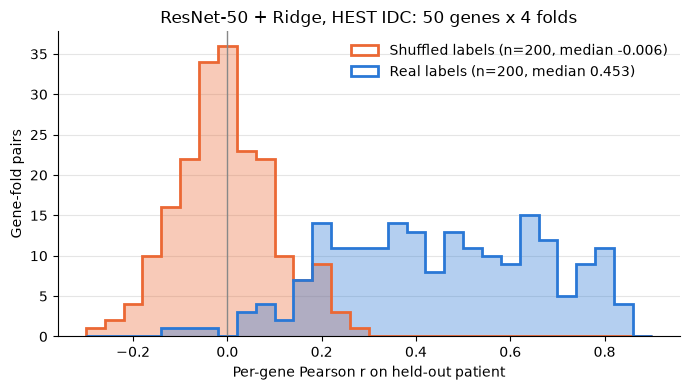

In [19]:
REAL_COLOR, SHUFFLED_COLOR = "#2a78d6", "#eb6834"
values = per_gene[["pearson_real", "pearson_shuffled"]].to_numpy()
bins = np.linspace(np.floor(np.nanmin(values) * 10) / 10, np.ceil(np.nanmax(values) * 10) / 10, 31)

fig, ax = plt.subplots(figsize=(7, 4))
for col, color, label in [("pearson_shuffled", SHUFFLED_COLOR, "Shuffled labels"), ("pearson_real", REAL_COLOR, "Real labels")]:
    vals = per_gene[col].dropna()
    ax.hist(vals, bins=bins, color=color, alpha=0.35)
    ax.hist(vals, bins=bins, color=color, histtype="step", linewidth=2,
            label=f"{label} (n={len(vals)}, median {vals.median():.3f})")
ax.axvline(0, color="#888888", linewidth=1)
ax.set_xlabel("Per-gene Pearson r on held-out patient")
ax.set_ylabel("Gene-fold pairs")
ax.set_title("ResNet-50 + Ridge, HEST IDC: 50 genes x 4 folds")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "pearson_hist_real_vs_shuffled.png", dpi=150)
plt.show()

In [20]:
# Per-gene results averaged over folds, best genes first
by_gene = per_gene.groupby("gene")[["pearson_real", "pearson_shuffled"]].mean().sort_values("pearson_real", ascending=False)
print("Top 10 genes (mean over folds):")
display(by_gene.head(10).round(3))
print("Bottom 5 genes:")
display(by_gene.tail(5).round(3))

Top 10 genes (mean over folds):


,pearson_real,pearson_shuffled
gene,,
TACSTD2,0.777,0.001
GATA3,0.773,0.090
ERBB2,0.722,-0.085
FASN,0.711,-0.023
SCD,0.690,-0.039
TOP2A,0.679,-0.001
KLF5,0.673,-0.040
ABCC11,0.664,-0.083
PTPRC,0.663,-0.015


Bottom 5 genes:


,pearson_real,pearson_shuffled
gene,,
SFRP1,0.175,0.020
OPRPN,0.174,-0.012
MMP12,0.149,0.014
TPSAB1,0.137,-0.012
MUC6,0.053,-0.044


## 8. Figures
All figures use the real-label results from Section 5 (and the shuffled control from Section 6 in (c)); each is saved to `results/`.

### (a) Observed vs predicted spatial maps

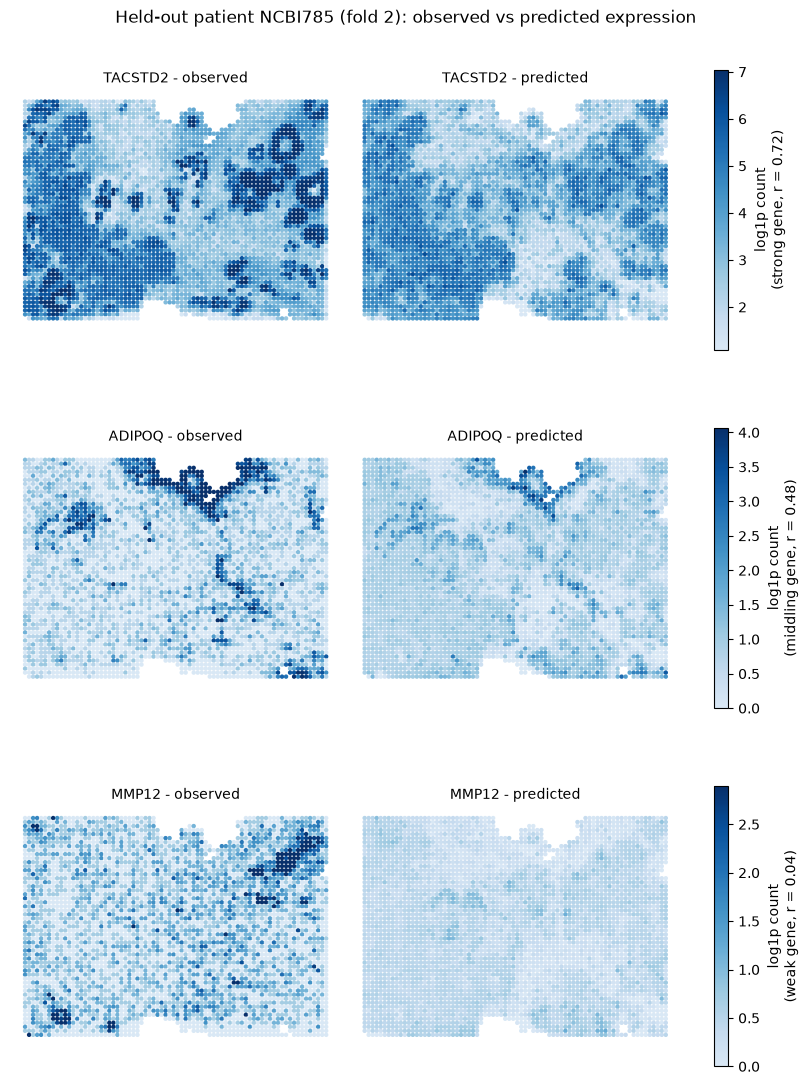

In [21]:
# Held-out patient for the maps: the fold whose mean r is closest to the average over folds (a typical patient)
fold_means = np.array([np.nanmean(real[fold]["r"]) for fold in range(4)])
MAP_FOLD = int(np.argmin(np.abs(fold_means - fold_means.mean())))
map_res = real[MAP_FOLD]
map_sample = map_res["test_id"]
valid = np.flatnonzero(np.isfinite(map_res["r"]))
order = valid[np.argsort(map_res["r"][valid])]  # weakest to strongest gene on this patient
map_genes = {"strong": order[-1], "middling": order[len(order) // 2], "weak": order[0]}

MAP_CMAP = ListedColormap(plt.cm.Blues(np.linspace(0.15, 1, 256)))  # single hue; lightest step stays visible on white
xy = expr[map_sample].obs[["pxl_col_in_fullres", "pxl_row_in_fullres"]].to_numpy()
spot_size = 40000 / len(xy)

fig, axes = plt.subplots(3, 2, figsize=(8, 11), layout="constrained")
for row, (label, g) in enumerate(map_genes.items()):
    observed, predicted = Y[map_sample][:, g], map_res["pred"][:, g]
    vmin, vmax = np.percentile(np.concatenate([observed, predicted]), [1, 99])  # one colour scale per gene
    for col, (kind, vals) in enumerate([("observed", observed), ("predicted", predicted)]):
        ax = axes[row, col]
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=vals, cmap=MAP_CMAP, vmin=vmin, vmax=vmax, s=spot_size, linewidths=0)
        ax.set_title(f"{GENES[g]} - {kind}", fontsize=10)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
    fig.colorbar(sc, ax=axes[row, :], shrink=0.8, label=f"log1p count\n({label} gene, r = {map_res['r'][g]:.2f})")
fig.suptitle(f"Held-out patient {map_sample} (fold {MAP_FOLD}): observed vs predicted expression")
fig.savefig(RESULTS_DIR / "fig_a_spatial_maps.png", dpi=150)
plt.show()


*(a)* On held-out patient NCBI785, the strong gene (TACSTD2, r = 0.72) and the middling gene (ADIPOQ, r = 0.48, mostly along the adipose border at the top) follow the observed tissue pattern, while the weak gene (MMP12, r = 0.04) is predicted as nearly flat and misses the observed hotspot; on the shared colour scale the predictions also span a narrower range than the observations, as expected from the strong Ridge shrinkage.

### (b) Gene × fold heatmap of Pearson r

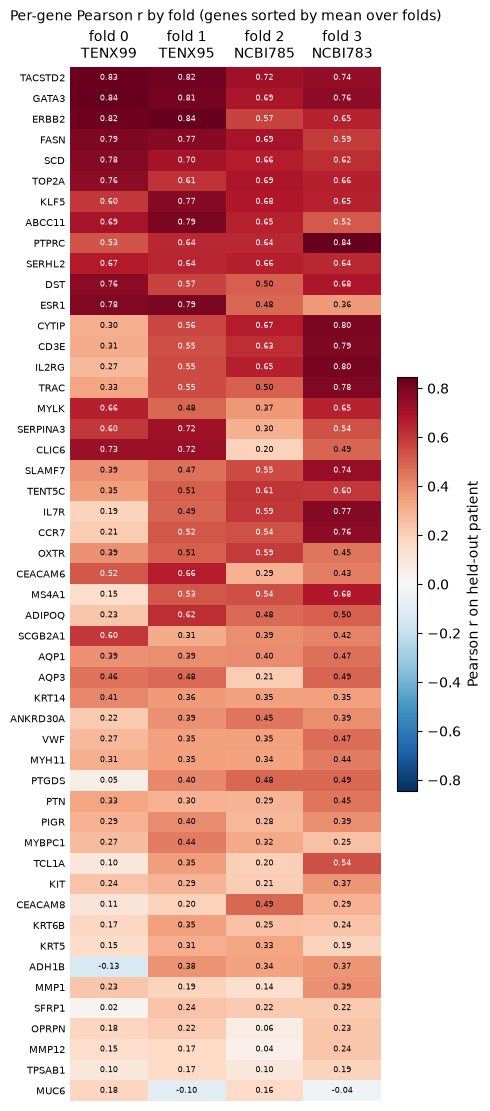

In [22]:
r_by_fold = per_gene.pivot(index="gene", columns="fold", values="pearson_real")
r_by_fold = r_by_fold.loc[r_by_fold.mean(axis=1).sort_values(ascending=False).index]
lim = np.nanmax(np.abs(r_by_fold.to_numpy()))

fig, ax = plt.subplots(figsize=(4.8, 11), layout="constrained")
im = ax.imshow(r_by_fold.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(4), [f"fold {fold}\n{real[fold]['test_id']}" for fold in r_by_fold.columns])
ax.xaxis.tick_top()
ax.set_yticks(range(len(r_by_fold)), r_by_fold.index, fontsize=7)
for i, j in np.ndindex(r_by_fold.shape):
    v = r_by_fold.iat[i, j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 * lim else "black")
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.4, label="Pearson r on held-out patient")
ax.set_title("Per-gene Pearson r by fold (genes sorted by mean over folds)", fontsize=10)
fig.savefig(RESULTS_DIR / "fig_b_gene_by_fold_heatmap.png", dpi=150)
plt.show()


*(b)* Epithelial/tumour genes such as TACSTD2, GATA3, ERBB2 and FASN are well predicted in every fold (r ≥ 0.57), whereas immune genes (CYTIP, CD3E, IL2RG, TRAC, IL7R, CCR7) range from 0.19–0.33 on TENX99 to 0.76–0.80 on NCBI783, so how well a gene transfers depends strongly on the held-out patient.

### (c) Per-fold distribution of per-gene r, real vs shuffled

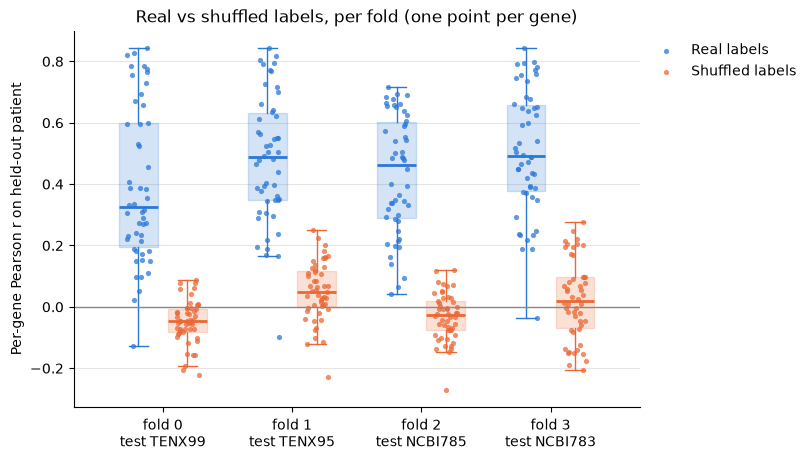

In [23]:
rng = np.random.default_rng(SEED)  # only for horizontal jitter of the points
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for k, (col, color, label) in enumerate([("pearson_real", REAL_COLOR, "Real labels"), ("pearson_shuffled", SHUFFLED_COLOR, "Shuffled labels")]):
    data = [per_gene.loc[per_gene["fold"] == fold, col].dropna() for fold in range(4)]
    positions = np.arange(4) + (k - 0.5) * 0.38
    ax.boxplot(data, positions=positions, widths=0.3, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.2, edgecolor=color), medianprops=dict(color=color, linewidth=2),
               whiskerprops=dict(color=color), capprops=dict(color=color))
    for i, (pos, d) in enumerate(zip(positions, data)):
        ax.scatter(pos + rng.uniform(-0.09, 0.09, len(d)), d, s=14, color=color, alpha=0.75, linewidths=0,
                   label=label if i == 0 else None)
ax.axhline(0, color="#888888", linewidth=1)
ax.set_xticks(range(4), [f"fold {fold}\ntest {real[fold]['test_id']}" for fold in range(4)])
ax.set_ylabel("Per-gene Pearson r on held-out patient")
ax.set_title("Real vs shuffled labels, per fold (one point per gene)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(RESULTS_DIR / "fig_c_per_fold_boxplot.png", dpi=150)
plt.show()


*(c)* In every fold the per-gene r with real labels sits well above the shuffled control, whose medians stay between −0.05 and 0.05; TENX99 (fold 0) has the lowest real-label median (0.32) and the widest spread.

### (d) Inner-CV score vs alpha

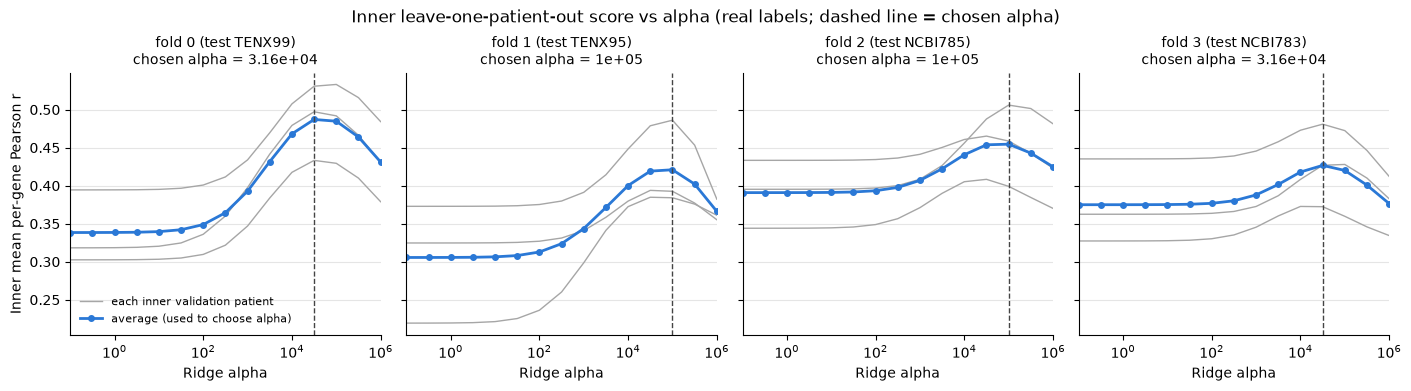

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True, layout="constrained")
for fold, ax in enumerate(axes):
    scores = real[fold]["scores"]
    for i, val_id in enumerate(scores.columns.drop("average")):
        ax.plot(scores.index, scores[val_id], color="#a6a6a6", linewidth=1,
                label="each inner validation patient" if i == 0 else None)
    ax.plot(scores.index, scores["average"], color=REAL_COLOR, linewidth=2, marker="o", markersize=4,
            label="average (used to choose alpha)")
    ax.axvline(real[fold]["alpha"], color="#444444", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(ALPHAS[0], ALPHAS[-1])
    ax.set_xlabel("Ridge alpha")
    ax.set_title(f"fold {fold} (test {real[fold]['test_id']})\nchosen alpha = {real[fold]['alpha']:.3g}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
axes[0].set_ylabel("Inner mean per-gene Pearson r")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Inner leave-one-patient-out score vs alpha (real labels; dashed line = chosen alpha)")
fig.savefig(RESULTS_DIR / "fig_d_inner_cv_vs_alpha.png", dpi=150)
plt.show()


*(d)* In every fold the inner leave-one-patient-out score is flat for small alpha, peaks at alpha = 3.16e4–1e5 and then falls, so the selected alpha now lies inside the grid rather than at its upper edge.

### (e) Gene predictability vs expression level

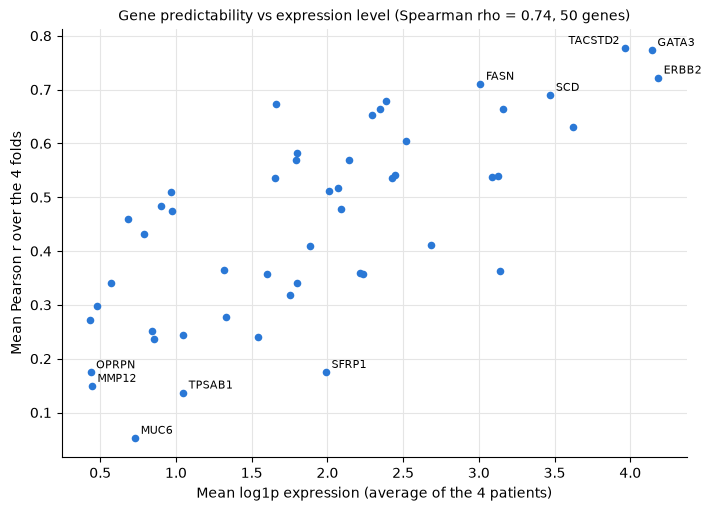

In [25]:
gene_stats = pd.DataFrame({
    "mean_log1p": pd.DataFrame({s: Y[s].mean(axis=0) for s in SAMPLES}, index=GENES).mean(axis=1),  # each patient weighted equally
    "mean_r": per_gene.groupby("gene")["pearson_real"].mean()})
rho = gene_stats.corr(method="spearman").loc["mean_log1p", "mean_r"]
extremes = pd.concat([gene_stats.nlargest(5, "mean_r"), gene_stats.nsmallest(5, "mean_r")])

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.scatter(gene_stats["mean_log1p"], gene_stats["mean_r"], s=30, color=REAL_COLOR, linewidths=0)
for gene, row in extremes.iterrows():
    # put the label on the left when another labelled gene sits just to the right at almost the same height
    crowded = ((extremes["mean_log1p"] > row["mean_log1p"]) & (extremes["mean_log1p"] - row["mean_log1p"] < 0.4)
               & ((extremes["mean_r"] - row["mean_r"]).abs() < 0.02)).any()
    ax.annotate(gene, (row["mean_log1p"], row["mean_r"]), xytext=(-4, 3) if crowded else (4, 3),
                textcoords="offset points", ha="right" if crowded else "left", fontsize=8)
ax.set_xlabel("Mean log1p expression (average of the 4 patients)")
ax.set_ylabel("Mean Pearson r over the 4 folds")
ax.set_title(f"Gene predictability vs expression level (Spearman rho = {rho:.2f}, 50 genes)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
fig.savefig(RESULTS_DIR / "fig_e_r_vs_expression.png", dpi=150)
plt.show()


*(e)* Genes with higher mean expression tend to be predicted better (Spearman rho = 0.74 across the 50 genes), and the least predictable genes (MUC6, TPSAB1, MMP12, OPRPN) are lowly expressed, with SFRP1 as an exception at moderate expression; this is a correlation only and does not by itself separate image signal from measurement noise.